# Tender GT EDA — diversity for GLiNER fine-tune

Source: `notebooks/evaluation/tender_offers.csv` (Evaluation branch GT).

**Question:** is the GT diverse enough to train GLiNER, or is it skewed toward one tender pattern?

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("../..").resolve()
GT_PATH = ROOT / "notebooks" / "evaluation" / "tender_offers.csv"

# GLiNER-oriented core fields (same set as eval CORE_GT_FIELDS)
CORE_GT_FIELDS = [
    "subject_company",
    "bidder",
    "security_description",
    "cusip",
    "isin",
    "ticker",
    "offer_price",
    "currency",
    "expiration_date",
    "withdrawal_deadline",
    "settlement_date",
    "effective_date",
    "minimum_tender_condition",
    "proration_terms",
]

META = {
    "corporate_action_type",
    "event_id",
    "passages",
    "accession_number",
    "form",
    "filing_date",
    "registrant_name",
    "registrant_cik",
    "action",
    "filing_id",
    "filing_index_url",
    "document_count",
    "text_byte_count",
    "text_size_mb",
    "input_hash",
    "status",
    "relevance",
    "input_coverage",
    "error",
}

MISSING = {"", "n/a", "na", "none", "-", "null", "nan"}


def is_missing(v) -> bool:
    if pd.isna(v):
        return True
    return str(v).strip().lower() in MISSING


df = pd.read_csv(GT_PATH)
GT_VALUE_FIELDS = [c for c in df.columns if c not in META]
df["filing_dt"] = pd.to_datetime(df["filing_date"], errors="coerce")
df["self_tender"] = [
    (not is_missing(b) and not is_missing(s) and str(b).strip().lower() == str(s).strip().lower())
    for b, s in zip(df["bidder"], df["subject_company"])
]

print(f"rows={len(df)}  accessions={df.accession_number.nunique()}  companies={df.subject_company.nunique()}")
print(f"date range: {df.filing_dt.min().date()} → {df.filing_dt.max().date()}")
df.head(2)

rows=613  accessions=507  companies=260
date range: 2026-01-02 → 2026-09-24


,corporate_action_type,event_id,subject_company,bidder,parent,acquisition_subsidiary,dealer_manager,depositary,information_agent,other_parties,...,document_count,text_byte_count,text_size_mb,input_hash,status,relevance,input_coverage,error,filing_dt,self_tender
0,Tender offer,tender_offer_0001859919-26-000002,Barings Private Credit Corporation,Barings Private Credit Corporation,NaN,NaN,NaN,NaN,NaN,"DST Systems, Inc. (transfer agent)",...,2,9738,0.010,68b79bcb7bcf8b411c92f355cd7730c6706a8a95cc2472...,ok,candidate_not_verified,selected filing and attached exhibits only; in...,NaN,2026-01-02,True
1,Tender offer,tender_offer_0001213900-26-000471,SEG Partners Long/Short Equity Fund,SEG Partners Long/Short Equity Fund,NaN,NaN,NaN,NaN,NaN,"Select Equity Group, L.P. (investment adviser)...",...,9,136126,0.136,626e698b65a7039b0ba24a44ce61bb5236edc5fd1b97e5...,ok,candidate_not_verified,selected filing and attached exhibits only; in...,NaN,2026-01-02,True


## 1. Corpus shape (filing / form / offer mix)

GLiNER learns surface patterns. If almost everything is **issuer self-tender (SC TO-I)** with **formula NAV** pricing, third-party cash TO-T patterns will stay weak.

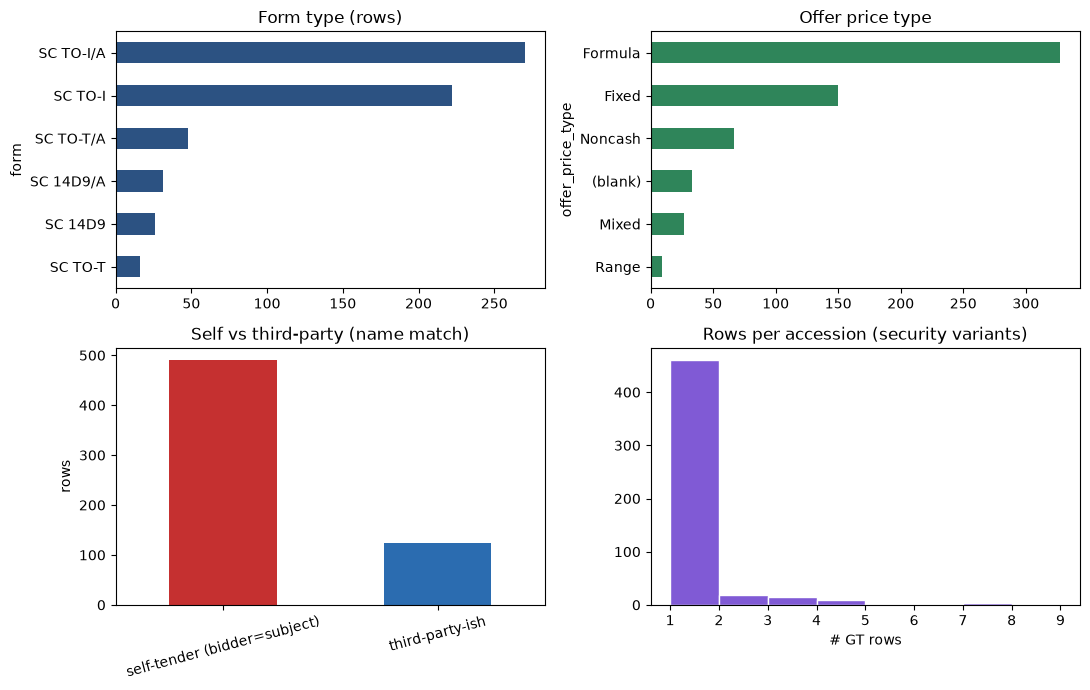

form %:
 form
SC TO-I/A    44.0
SC TO-I      36.2
SC TO-T/A     7.8
SC 14D9/A     5.1
SC 14D9       4.2
SC TO-T       2.6

mandatory/voluntary:
 mandatory_voluntary_indicator
Voluntary    613

self-tender rows: 79.9%  |  accessions with >1 row: 9.3%


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

df["form"].value_counts().plot.barh(ax=axes[0, 0], color="#2c5282")
axes[0, 0].set_title("Form type (rows)")
axes[0, 0].invert_yaxis()

df["offer_price_type"].fillna("(blank)").value_counts().plot.barh(ax=axes[0, 1], color="#2f855a")
axes[0, 1].set_title("Offer price type")
axes[0, 1].invert_yaxis()

pd.Series(
    {"self-tender (bidder=subject)": df.self_tender.sum(), "third-party-ish": (~df.self_tender).sum()}
).plot.bar(ax=axes[1, 0], color=["#c53030", "#2b6cb0"], rot=15)
axes[1, 0].set_title("Self vs third-party (name match)")
axes[1, 0].set_ylabel("rows")

rows_per = df.groupby("accession_number").size()
axes[1, 1].hist(rows_per, bins=range(1, int(rows_per.max()) + 2), color="#805ad5", edgecolor="white")
axes[1, 1].set_title("Rows per accession (security variants)")
axes[1, 1].set_xlabel("# GT rows")

plt.tight_layout()
plt.show()

print("form %:\n", (df.form.value_counts(normalize=True) * 100).round(1).to_string())
print("\nmandatory/voluntary:\n", df.mandatory_voluntary_indicator.value_counts(dropna=False).to_string())
print(f"\nself-tender rows: {df.self_tender.mean():.1%}  |  accessions with >1 row: {(rows_per > 1).mean():.1%}")

## 2. Core field fill + uniqueness

Fill rate = how often the label exists. Uniqueness / value-length = whether spans are repetitive templates (bad for generalization) or varied (good).

In [3]:
rows = []
for col in CORE_GT_FIELDS:
    mask = ~df[col].map(is_missing)
    vals = df.loc[mask, col].astype(str).str.strip()
    rows.append(
        {
            "field": col,
            "filled": int(mask.sum()),
            "fill_rate": mask.mean(),
            "n_unique": int(vals.nunique()) if len(vals) else 0,
            "uniq_rate": (vals.nunique() / len(vals)) if len(vals) else 0.0,
            "len_med": float(vals.str.len().median()) if len(vals) else np.nan,
            "len_p90": float(vals.str.len().quantile(0.9)) if len(vals) else np.nan,
        }
    )
core = pd.DataFrame(rows).sort_values("fill_rate")
core

,field,filled,fill_rate,n_unique,uniq_rate,len_med,len_p90
11,effective_date,27,0.044046,21,0.777778,9.0,204.8
7,currency,54,0.088091,1,0.018519,3.0,3.0
13,proration_terms,231,0.376835,209,0.904762,412.0,591.0
5,ticker,236,0.384992,84,0.355932,4.0,11.0
12,minimum_tender_condition,257,0.419250,48,0.186770,27.0,291.8
9,withdrawal_deadline,292,0.476346,194,0.664384,31.0,145.9
3,cusip,388,0.632953,165,0.425258,9.0,42.0
4,isin,388,0.632953,166,0.427835,12.0,54.0
10,settlement_date,407,0.663948,302,0.742015,137.0,328.0
8,expiration_date,537,0.876020,261,0.486034,31.0,36.0


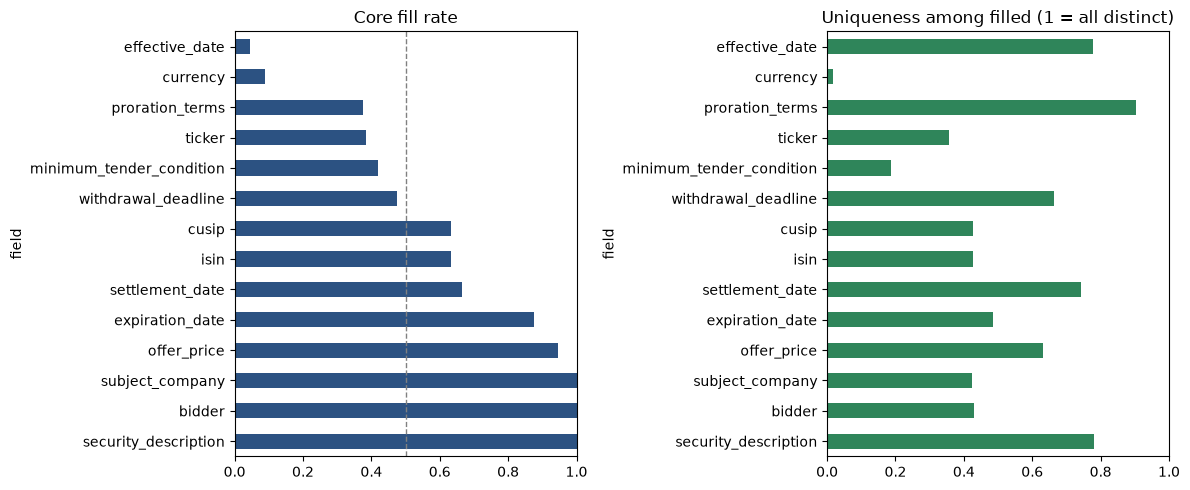

sparse (<50% fill): ['effective_date', 'currency', 'proration_terms', 'ticker', 'minimum_tender_condition', 'withdrawal_deadline']
low diversity among filled (uniq_rate < 0.25): ['minimum_tender_condition']


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot = core.set_index("field")
plot["fill_rate"].plot.barh(ax=axes[0], color="#2c5282")
axes[0].axvline(0.5, color="gray", ls="--", lw=1)
axes[0].set_xlim(0, 1)
axes[0].set_title("Core fill rate")
axes[0].invert_yaxis()

plot["uniq_rate"].plot.barh(ax=axes[1], color="#2f855a")
axes[1].set_xlim(0, 1)
axes[1].set_title("Uniqueness among filled (1 = all distinct)")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

sparse = core[core.fill_rate < 0.5]["field"].tolist()
templatey = core[(core.fill_rate >= 0.4) & (core.uniq_rate < 0.25)]["field"].tolist()
print("sparse (<50% fill):", sparse or "none")
print("low diversity among filled (uniq_rate < 0.25):", templatey or "none")

## 3. Value-shape checks (price / IDs / parties)

Quick look at whether filled values look like short copyable spans (GLiNER-friendly) vs long prose.

In [5]:
def sample_vals(col: str, n: int = 8) -> pd.Series:
    s = df.loc[~df[col].map(is_missing), col].astype(str).str.strip()
    return s.drop_duplicates().head(n)


for col in [
    "offer_price",
    "security_description",
    "expiration_date",
    "minimum_tender_condition",
    "currency",
    "cusip",
]:
    s = df.loc[~df[col].map(is_missing), col].astype(str)
    print(f"\n=== {col} (filled={len(s)}, unique={s.nunique()}) ===")
    print(s.value_counts().head(5).to_string())
    print("samples:", list(sample_vals(col, 3)))


=== offer_price (filled=580, unique=367) ===
offer_price
30.00                                                                                                             21
Net asset value per Share as of March 31, 2026 or a later date determined by the Fund if the Offer is extended    17
net asset value per Share as of December 31, 2025                                                                 16
100% of the Shareholder’s unaudited net asset value of the Shares tendered                                        12
Net asset value of the tendered Shares as of the Valuation Date                                                   10
samples: ['Net asset value per Share as of December 31, 2025', 'Net asset value as of March 31, 2026, or a later Valuation Date if the Offer is extended, less any Early Repurchase Fee', 'Net asset value of the tendered shares as of the Valuation Date']

=== security_description (filled=613, unique=479) ===
security_description
Warner Bros. Discovery, Inc.

/var/folders/xm/qd3sjdt122zgy4slwbcb9m6c0000gn/T/ipykernel_15749/1642713949.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, tick_labels=labels, vert=False, showfliers=False)


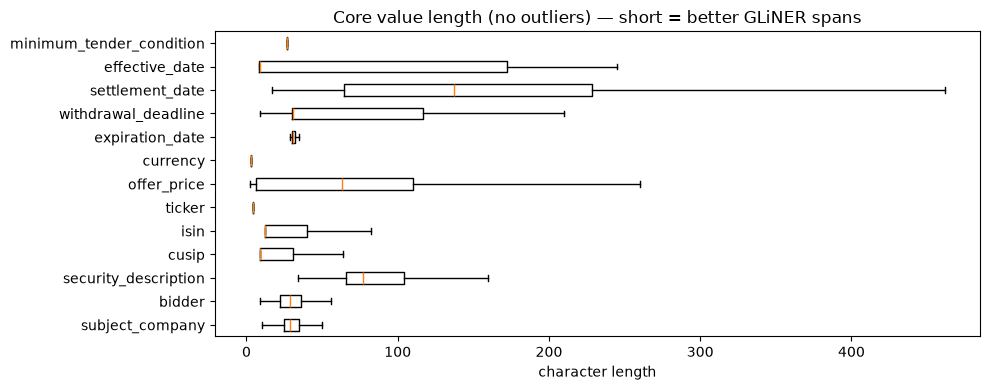

proration_terms length: n=231 med=412 p90=591 (often too long for clean spans)


In [6]:
span_cols = [c for c in CORE_GT_FIELDS if c not in {"proration_terms"}]
fig, ax = plt.subplots(figsize=(10, 4))
data, labels = [], []
for c in span_cols:
    lens = df.loc[~df[c].map(is_missing), c].astype(str).str.len()
    if len(lens):
        data.append(lens)
        labels.append(c)
ax.boxplot(data, tick_labels=labels, vert=False, showfliers=False)
ax.set_xlabel("character length")
ax.set_title("Core value length (no outliers) — short = better GLiNER spans")
plt.tight_layout()
plt.show()

long = df.loc[~df["proration_terms"].map(is_missing), "proration_terms"].astype(str).str.len()
print(
    f"proration_terms length: n={len(long)} med={long.median():.0f} p90={long.quantile(0.9):.0f} (often too long for clean spans)"
)

## 4. Train/holdout sketch

GLiNER FT should split on **accession**. Check how many distinct accessions / companies you actually have.

In [7]:
def core_fill_row(r) -> float:
    return float(np.mean([not is_missing(r[c]) for c in CORE_GT_FIELDS]))


df["core_fill"] = df.apply(core_fill_row, axis=1)
acc = (
    df.groupby("accession_number", as_index=False)
    .agg(
        n_rows=("event_id", "size"),
        form=("form", "first"),
        subject=("subject_company", "first"),
        self_tender=("self_tender", "all"),
        price_type=("offer_price_type", "first"),
        mean_core_fill=("core_fill", "mean"),
    )
)

print(acc[["form", "self_tender", "price_type"]].astype(str).value_counts().head(12).to_string())
print()
print(acc["mean_core_fill"].describe().round(3).to_string())
print(f"\naccessions with mean core fill < 0.5: {(acc.mean_core_fill < 0.5).sum()} / {len(acc)}")

form       self_tender  price_type
SC TO-I    True         Formula       159
SC TO-I/A  True         Formula       116
                        Fixed          31
SC TO-T/A  False        Fixed          31
SC TO-I/A  True         Noncash        25
SC 14D9/A  False        Fixed          21
SC 14D9    False        Fixed          18
SC TO-I    True         Fixed          16
SC TO-T    False        Fixed          12
SC TO-I    True         Noncash        11
SC TO-T/A  False        Mixed           9
SC 14D9/A  False        Mixed           7

count    507.000
mean       0.615
std        0.154
min        0.286
25%        0.500
50%        0.643
75%        0.786
max        0.929

accessions with mean core fill < 0.5: 98 / 507


## 5. Diversity verdict (for GLiNER)

In [8]:
n_acc = df.accession_number.nunique()
to_i_share = df.form.str.contains("TO-I", na=False).mean()
to_t_share = df.form.str.contains("TO-T", na=False).mean()
self_share = df.self_tender.mean()
formula_share = (df.offer_price_type.fillna("").str.lower() == "formula").mean()
fixed_share = (df.offer_price_type.fillna("").str.lower() == "fixed").mean()
years = sorted({int(y) for y in df.filing_dt.dt.year.dropna().unique()})

checks = [
    ("≥80 distinct accessions", n_acc >= 80, f"{n_acc}"),
    ("≥2 filing years", len(years) >= 2, str(years)),
    ("third-party TO-T ≥15% of rows", to_t_share >= 0.15, f"{to_t_share:.1%}"),
    ("self-tender ≤70% of rows", self_share <= 0.70, f"{self_share:.1%}"),
    ("fixed-price ≥20% of rows", fixed_share >= 0.20, f"{fixed_share:.1%}"),
    ("SC TO-I share ≤70%", to_i_share <= 0.70, f"{to_i_share:.1%}"),
    ("ticker fill ≥40%", (~df.ticker.map(is_missing)).mean() >= 0.40, f"{(~df.ticker.map(is_missing)).mean():.1%}"),
    (
        "currency has >1 unique when filled",
        df.loc[~df.currency.map(is_missing), "currency"].nunique() > 1,
        str(df.loc[~df.currency.map(is_missing), "currency"].nunique()),
    ),
]

verdict = pd.DataFrame([{"check": c, "pass": p, "value": v} for c, p, v in checks])
display(verdict)

passed = int(verdict["pass"].sum())
print(f"\nPassed {passed}/{len(verdict)} diversity checks.")
if passed >= 6:
    print("Verdict: OK to fine-tune; still watch sparse/templatey fields.")
elif passed >= 4:
    print("Verdict: Usable for a narrow GLiNER (issuer / fund self-tenders), not general tender IE.")
else:
    print("Verdict: Too skewed — add TO-T / fixed-price / older years before expecting broad FT gains.")

,check,pass,value
0,≥80 distinct accessions,True,507
1,≥2 filing years,False,[2026]
2,third-party TO-T ≥15% of rows,False,10.4%
3,self-tender ≤70% of rows,False,79.9%
4,fixed-price ≥20% of rows,True,24.5%
5,SC TO-I share ≤70%,False,80.3%
6,ticker fill ≥40%,False,38.5%
7,currency has >1 unique when filled,False,1



Passed 2/8 diversity checks.
Verdict: Too skewed — add TO-T / fixed-price / older years before expecting broad FT gains.


### Optional: full GT fill heatmap (all value fields)

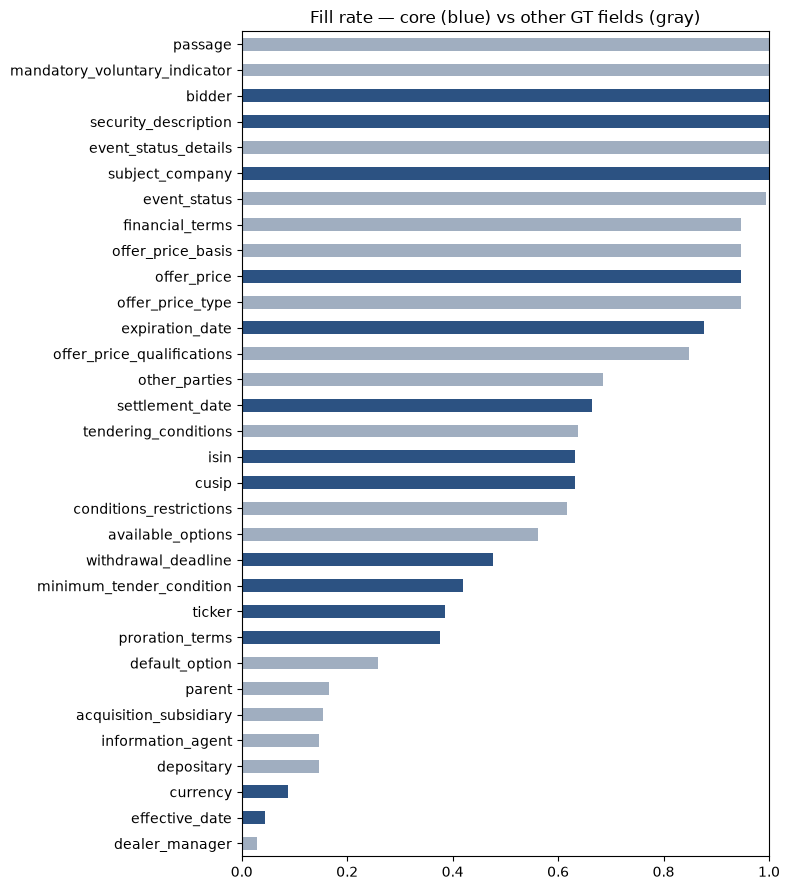

In [9]:
fill_all = pd.Series({c: (~df[c].map(is_missing)).mean() for c in GT_VALUE_FIELDS}).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
fill_all.plot.barh(
    ax=ax,
    color=["#2c5282" if c in CORE_GT_FIELDS else "#a0aec0" for c in fill_all.index],
)
ax.set_xlim(0, 1)
ax.set_title("Fill rate — core (blue) vs other GT fields (gray)")
plt.tight_layout()
plt.show()